# 11. Single-Layer Perceptron

One neuron with a sigmoid output trained by SGD with momentum on the weighted log loss (+ L2) - the
neural-network view of logistic regression. A strong learning-rate decay keeps the loss curve smooth
on correlated features.

From-scratch code: `ClassificationAlgorithms/Perceptron.py` · charts: `Images/Classification/11_Single_Layer_Perceptron/` · tables: `Results/Classification/11_Single_Layer_Perceptron/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
from project import SEED, Outputs, classification_data, imbalance_weight
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from Perceptron import SingleLayerPerceptronScratch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

out = Outputs("Classification", "11_Single_Layer_Perceptron")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it (validation set = early stopping)
model = SingleLayerPerceptronScratch(learning_rate=0.05, n_epochs=300, l2=1e-3, lr_decay=0.3, random_state=SEED)
check_settings("Single-Layer Perceptron", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: trained to convergence, it must reach the same weights as LogisticRegression on the SAME loss
w_tr = imbalance_weight(d.y_tr)
sc = StandardScaler().fit(d.X_tr)
slp_full = SingleLayerPerceptronScratch(
    learning_rate=0.05, n_epochs=400, l2=1e-3, lr_decay=0.02, random_state=SEED
).fit(d.X_tr, d.y_tr, early_stopping_rounds=0)
sk = LogisticRegression(C=1 / (1e-3 * w_tr.sum()), max_iter=5000, tol=1e-10).fit(
    sc.transform(d.X_tr), d.y_tr, sample_weight=w_tr
)
check = sklearn_check(
    "Single-layer perceptron vs LogisticRegression (same loss)",
    np.abs(slp_full.coef_ - sk.coef_[0]).max(),
    roc_auc(d.y_te, slp_full.predict_proba(d.X_te)[:, 1]),
    roc_auc(d.y_te, sk.predict_proba(sc.transform(d.X_te))[:, 1]),
    "max |dcoef|",
)

settings match Common/model_zoo.py (8 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2207        0.5000
log loss                            0.4604           NaN
accuracy                            0.4400        0.8116
precision                           0.2037        0.3409
recall / sensitivity                0.8656        0.1967
specificity                         0.3594           NaN
F1                                  0.3298        0.2495
ROC-AUC                             0.7050           NaN
PR-AUC                              0.2970           NaN
defaulters missed (FN)             41.0000           NaN

catches 86.6% of the 305 test defaulters (41 missed), flags 67.6% of applicants


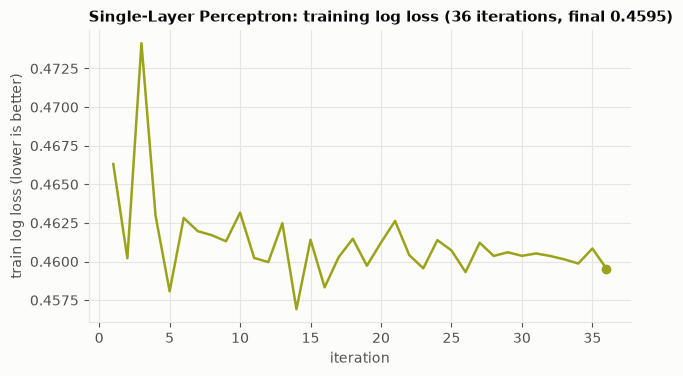

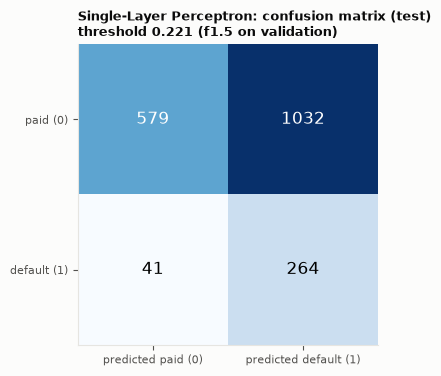

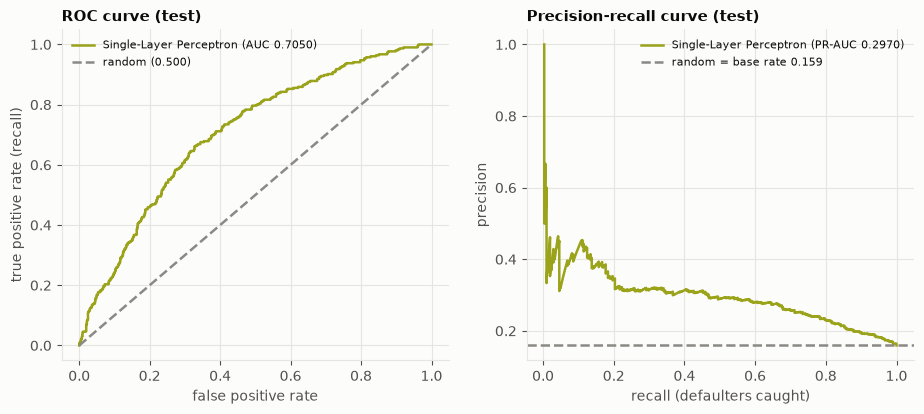

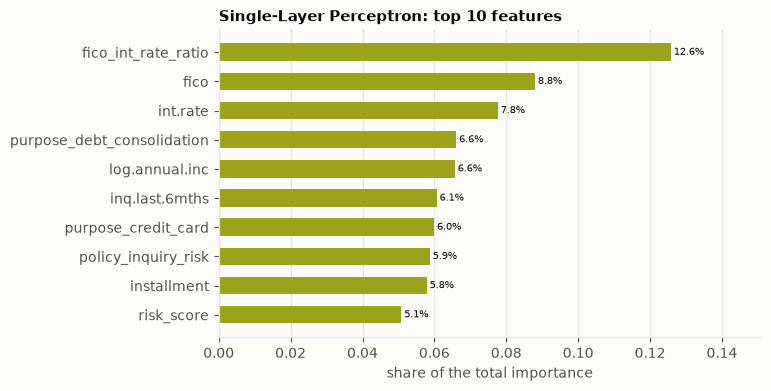


scratch vs library:
  Single-layer perceptron vs LogisticRegression (same loss)
    AUC scratch 0.7041 | AUC library 0.7051 | max |dcoef| = 0.00885

saved + reloaded TrainedModels/Classification/11_Single_Layer_Perceptron.joblib (identical predictions: True)


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "Single-Layer Perceptron", model, d, check)